# Automatic differentiation with PyTorch (Pyro sample)

`dark_emulator2.autodiff.TorchEmulator` returns the same `P(k)` and `C_ell` as `DarkEmulator2` (emulator method) as torch tensors connected to the autograd graph of the input parameters. Derivatives with respect to the cosmological parameters are therefore available, and the emulator can be used inside gradient-based samplers such as NUTS in Pyro.

This notebook checks the outputs against `DarkEmulator2`, shows parameter derivatives, and runs NUTS on a toy `C_ell` likelihood. It is not a survey analysis: real data vectors, covariances, nuisance parameters, scale cuts, and emulator/theory uncertainty treatment must be supplied by the downstream analysis.

Pyro documentation: https://docs.pyro.ai/

## Setup

Use the same Python environment as this notebook kernel. Pass `device="cuda"` to run the networks on a GPU.

In [1]:
# %pip install pyro-ppl dark_emulator2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import pyro
import pyro.distributions as dist
from pyro.infer import MCMC, NUTS
from dark_emulator2 import DarkEmulator2
from dark_emulator2.autodiff import TorchEmulator

device = "cuda" if torch.cuda.is_available() else "cpu"
de = DarkEmulator2()
emu = TorchEmulator(de, device=device, dtype=torch.float64)

fiducial = {
    "Omega_m": 0.3156,
    "h0": 0.6723,
    "omega_b": 0.02225,
    "sigma8": 0.831,
    "ns": 0.9645,
    "Mnu": 0.06,
    "Omega_k": 0.0,
    "w0": -1.0,
    "wa": 0.0,
}

## Same outputs as `DarkEmulator2`

Parameters can be Python floats or tensors with a common batch shape. Outputs have the shape `(batch..., nz, nk)` for `P(k)` and `(batch..., nl)` for `C_ell`.

In [3]:
zred = [0.0, 0.5, 1.0]
k, pk = emu.get_pk(fiducial, zred=zred, pk_type="total")
_, pk_ref = de.get_pk(fiducial, zred=zred, pk_type="total")
print("P(k)  max relative difference:", np.max(np.abs(pk.cpu().numpy() / pk_ref - 1)))

ell, cl = emu.get_cl_limber(fiducial)
_, cl_ref = de.get_cl_limber(fiducial)
print("C_ell max relative difference:", np.max(np.abs(cl.cpu().numpy() / cl_ref - 1)))

P(k)  max relative difference: 8.629884120647802e-07


C_ell max relative difference: 5.554367672466753e-07


## Parameter derivatives

Derivatives of `ln P(k)` at `z = 0` and of `ln C_ell` with respect to a few parameters, computed with `torch.func.jacfwd` (forward-mode autodiff, one pass per parameter).

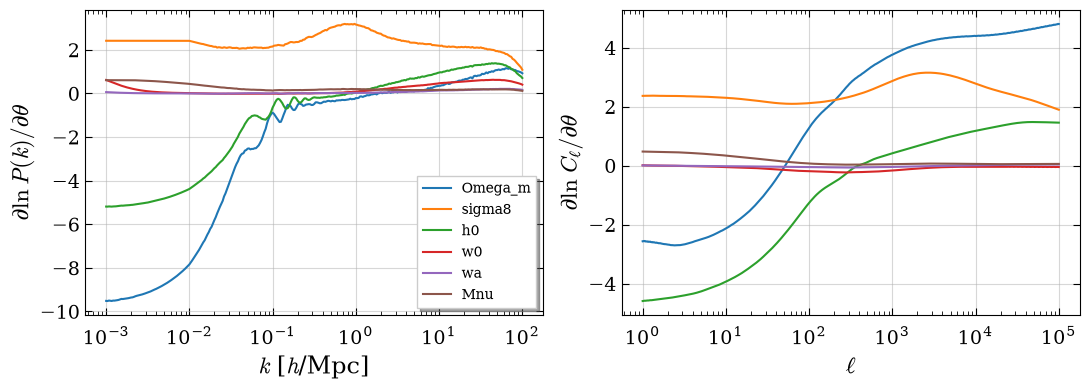

In [4]:
names = ["Omega_m", "sigma8", "h0", "w0", "wa", "Mnu"]
theta = torch.tensor([fiducial[n] for n in names], dtype=torch.float64, device=device)


def params_from(theta):
    return {**fiducial, **dict(zip(names, theta))}


jac_pk = torch.func.jacfwd(lambda t: torch.log(emu.get_pk(params_from(t), zred=0.0)[1]))(theta)
jac_cl = torch.func.jacfwd(lambda t: torch.log(emu.get_cl_limber(params_from(t))[1]))(theta)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, name in enumerate(names):
    axes[0].semilogx(k.cpu(), jac_pk[:, i].cpu(), label=name)
    axes[1].semilogx(ell.cpu(), jac_cl[:, i].cpu(), label=name)
axes[0].set_xlabel(r"$k$ [$h$/Mpc]")
axes[0].set_ylabel(r"$\partial \ln P(k) / \partial \theta$")
axes[1].set_xlabel(r"$\ell$")
axes[1].set_ylabel(r"$\partial \ln C_\ell / \partial \theta$")
axes[0].legend()
plt.tight_layout()
plt.show()

## Toy `C_ell` likelihood and NUTS

The fake data vector is generated at `Omega_m = 0.45`, `sigma8 = 0.62` with a 5% error on `ln C_ell`, the same setup as the CosmoSIS and Cobaya samples. `Omega_m` and `sigma8` are sampled with uniform priors and the other parameters are fixed.

NUTS needs a smooth target, so the prior box is chosen inside the practical Dark Emulator2 support instead of rejecting points outside it. The four corners of the box are checked below.

Each NUTS step evaluates the emulator and its gradient at all redshifts in `z_cl`, so the sampling cell takes a few minutes on a CPU.

In [5]:
z_cl = np.linspace(0.0, 2.0, 101)
k_cl = np.logspace(-3, 1, 201)
ell_data = np.logspace(1, 4, 40)
sigma_logcl = 0.05
data_omega_m, data_sigma8 = 0.45, 0.62
omega_m_prior, sigma8_prior = (0.40, 0.50), (0.56, 0.68)

print("prior box corners in support:",
      [de.is_in_support({**fiducial, "Omega_m": om, "sigma8": s8}) for om in omega_m_prior for s8 in sigma8_prior])

_, cl_data = emu.get_cl_limber({**fiducial, "Omega_m": data_omega_m, "sigma8": data_sigma8}, zlist=z_cl, klist=k_cl, llist=ell_data)
log_cl_data = torch.log(cl_data)


def uniform(lo, hi):
    return dist.Uniform(torch.tensor(lo, dtype=torch.float64, device=device), torch.tensor(hi, dtype=torch.float64, device=device))


def model():
    omega_m = pyro.sample("Omega_m", uniform(*omega_m_prior))
    sigma8 = pyro.sample("sigma8", uniform(*sigma8_prior))
    _, cl = emu.get_cl_limber({**fiducial, "Omega_m": omega_m, "sigma8": sigma8}, zlist=z_cl, klist=k_cl, llist=ell_data)
    pyro.sample("obs", dist.Normal(torch.log(cl), sigma_logcl).to_event(1), obs=log_cl_data)

prior box corners in support: [True, True, True, True]


In [6]:
pyro.set_rng_seed(0)
mcmc = MCMC(NUTS(model), num_samples=200, warmup_steps=100, disable_progbar=True)
mcmc.run()
mcmc.summary()
samples = {name: value.cpu().numpy() for name, value in mcmc.get_samples().items()}


                mean       std    median      5.0%     95.0%     n_eff     r_hat
   Omega_m      0.45      0.01      0.45      0.44      0.46     54.12      1.00
    sigma8      0.62      0.00      0.62      0.61      0.62     51.63      1.00

Number of divergences: 0


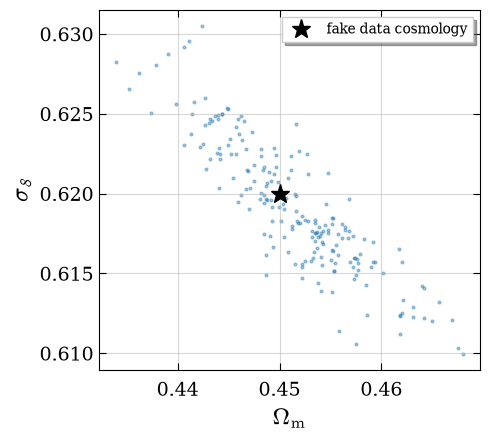

In [7]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(samples["Omega_m"], samples["sigma8"], s=4, alpha=0.4)
ax.plot(data_omega_m, data_sigma8, "*", color="k", ms=14, label="fake data cosmology")
ax.set_xlabel(r"$\Omega_{\rm m}$")
ax.set_ylabel(r"$\sigma_8$")
ax.legend()
plt.tight_layout()
plt.show()

## Notes for real data analyses

Keep the call pattern, but replace the fake data vector, toy error, nuisance parameters, scale cuts and likelihood conventions with those required by the target analysis.

- The parameter values can be scalars or arrays with a common batch shape. The grids (`zred`, `klist`, `zlist`, `llist`, `src_dist`) must be fixed numpy arrays; the tables that depend on them are computed once and reused.
- Double precision is recommended for HMC. The networks were trained in single precision, so outputs differ from `DarkEmulator2` at the 1e-6 level.
- NUTS needs a smooth posterior. Keep the prior inside the practical Dark Emulator2 support (`DarkEmulator2.is_in_support`) or add a smooth penalty near its boundary instead of a hard cut.
- The `C_ell` output uses the same shot-noise treatment as `DarkEmulator2.get_cl_limber`, whose cutoff index depends on the parameters; derivatives are exact between those switches.
- For production use, pass `P(k,z)` to the downstream projection and likelihood calculation when the workflow supports it.